# Hierarchical Clustering

## Intuition

Hierarchical Clustering builds a **tree of clusters** (called a dendrogram) by either:

- **Agglomerative** (bottom-up): Start with individual points and **merge** them step by step.
- **Divisive** (top-down): Start with one cluster and **split** it recursively.

We focus on **Agglomerative Clustering**, the most common approach.

No need to specify number of clusters initially, you can "cut" the dendrogram at any height.


## Mathematical Foundation

The clustering is based on **distance between points or clusters**.

### Distance Metrics:
- **Euclidean** (default): $d(x, y) = \sqrt{\sum (x_i - y_i)^2}$
- Manhattan, Cosine, etc.

### Linkage Criteria:
Defines distance between clusters:
- **Single Linkage**: min distance between any pair of points
- **Complete Linkage**: max distance between any pair
- **Average Linkage**: mean distance
- **Ward’s Method**: minimizes within-cluster variance (similar to K-Means)

Most common: **Ward’s method + Euclidean distance**

## Agglomerative Hierarchical Clustering Steps

1. Treat each data point as a **separate cluster**
2. Compute **pairwise distances** between all clusters
3. **Merge** the closest two clusters
4. Recompute distances using chosen **linkage method**
5. Repeat until **all points belong to one cluster**

This process builds a **dendrogram**, and you can cut it at any height to choose number of clusters.

## Do You Need to Specify Number of Clusters?

Unlike K-Means, **Hierarchical Clustering builds the full hierarchy first** (as a dendrogram), without needing to predefine the number of clusters.

However, to assign **final cluster labels** (i.e., cut the dendrogram), you **do need to specify the number of clusters (`k`) or a cut-off distance**.

So:
- You **don’t need to guess `k` before building** the model.
- You **choose `k` after inspecting the dendrogram visually.**


## Linkage Methods in Agglomerative Clustering

In hierarchical (agglomerative) clustering, **linkage methods** determine how the distance between two clusters is calculated when merging. Below are the four common linkage strategies:

---

### 1. **Ward Linkage**
- **Goal**: Minimize the total within-cluster **variance** (inertia).
- **Merging Criterion**: Choose the pair of clusters whose merger results in the **smallest increase** in total within-cluster **sum of squared errors (SSE)**.
- **Characteristics**:
  - Tends to create **compact and equally-sized** clusters.
  - Only supports **Euclidean distance**.

---

### 2. **Single Linkage (Minimum Linkage)**
- **Goal**: Merge clusters with the **closest pair of points**.
- **Characteristics**:
  - Can create **chained clusters** (loose, elongated shapes).
  - Sensitive to noise and outliers.

---

### 3. **Complete Linkage (Maximum Linkage)**
- **Goal**: Merge clusters with the **farthest pair of points**.
- **Characteristics**:
  - Produces **compact and spherical** clusters.
  - Sensitive to **outliers** and may break large clusters.

---

### 4. **Average Linkage (UPGMA)**
- **Goal**: Merge clusters based on the **average distance** between all pairs of points.
- **Characteristics**:
  - Balanced between single and complete.
  - Produces reasonable clustering in many cases.

---

### Summary Table

| Linkage Type | Based On         | Behavior                          |
|--------------|------------------|-----------------------------------|
| Ward         | Variance (SSE)   | Compact, equal-sized clusters     |
| Single       | Closest points   | Chained clusters, sensitive       |
| Complete     | Farthest points  | Tight clusters, sensitive         |
| Average      | Avg. pairwise    | Balanced merging strategy         |


In [ ]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
# Create synthetic dataset
X, y_true = make_blobs(n_samples=25, centers=3, cluster_std=1.0, random_state=42)

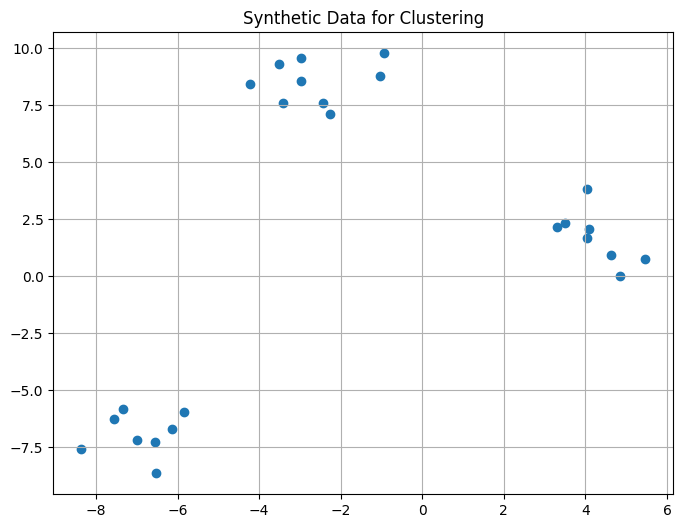

In [ ]:
# Plot
plt.figure(figsize=(8,6))
plt.scatter(X[:, 0], X[:, 1])
plt.title("Synthetic Data for Clustering")
plt.grid(True)
plt.show()

In [ ]:
import scipy.cluster.hierarchy as sch

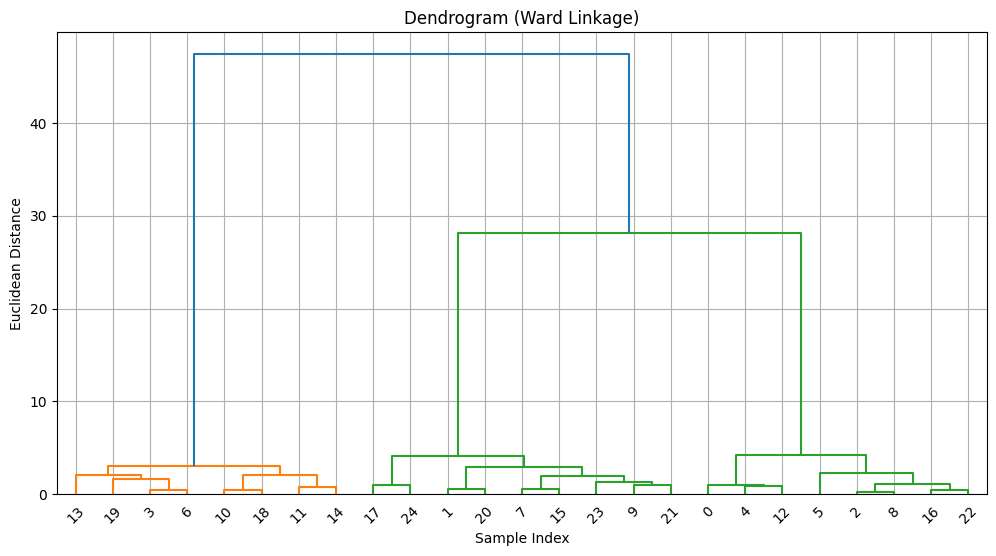

In [ ]:
# Plot dendrogram
plt.figure(figsize=(12,6))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'))
plt.title("Dendrogram (Ward Linkage)")
plt.xlabel("Sample Index")
plt.ylabel("Euclidean Distance")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering

In [ ]:
# Apply Agglomerative Clustering (cut dendrogram at n_clusters=3)
agg_clust = AgglomerativeClustering(n_clusters=3, linkage='ward')
y_pred = agg_clust.fit_predict(X)

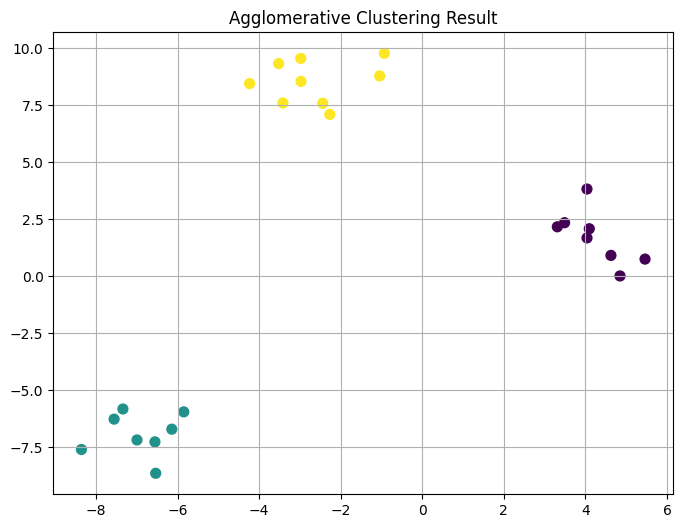

In [ ]:
# Plot clusters
plt.figure(figsize=(8,6))
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='viridis', s=50)
plt.title("Agglomerative Clustering Result")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.datasets import load_iris
import pandas as pd

In [ ]:
# Load Iris dataset
iris = load_iris()
X_iris = iris.data
df = pd.DataFrame(X_iris, columns=iris.feature_names)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


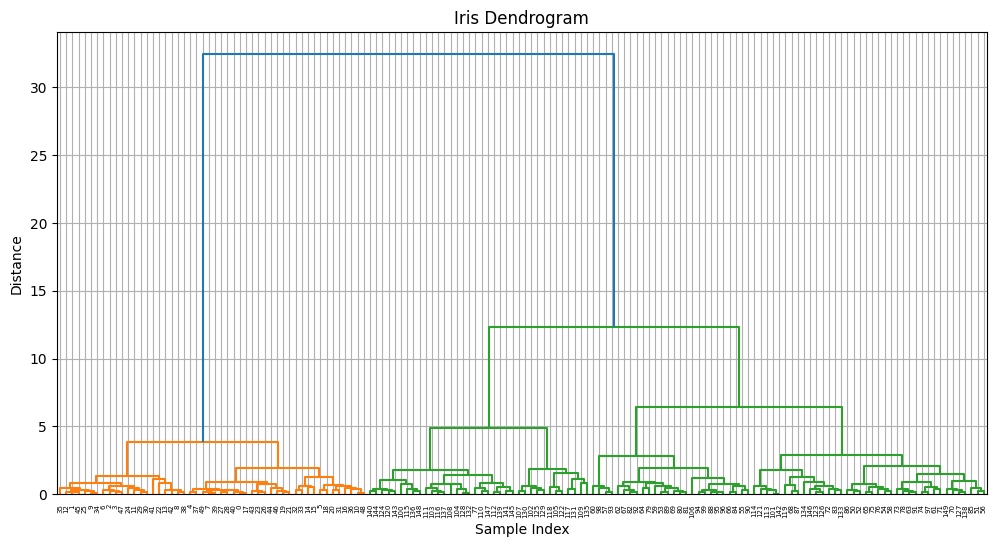

In [ ]:
plt.figure(figsize=(12,6))
dendrogram = sch.dendrogram(sch.linkage(X_iris, method='ward'))
plt.title("Iris Dendrogram")
plt.xlabel("Sample Index")
plt.ylabel("Distance")
plt.grid(True)
plt.show()

In [ ]:
agg_iris = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels = agg_iris.fit_predict(X_iris)

In [ ]:
df['Cluster'] = labels
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1


In [ ]:
from sklearn.decomposition import PCA

# Reduce to 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_iris)

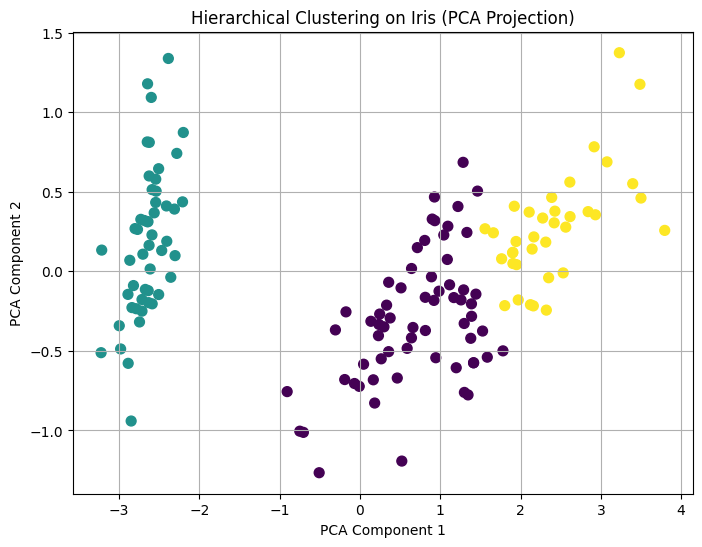

In [ ]:
# Plot clusters
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', s=50)
plt.title("Hierarchical Clustering on Iris (PCA Projection)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix

true_labels = iris.target
pred_labels = labels

confusion_matrix(true_labels, pred_labels)

array([[ 0, 50,  0],
       [49,  0,  1],
       [15,  0, 35]])

## Summary

- Hierarchical clustering builds nested clusters via **dendrograms**
- Most common is **Agglomerative Clustering** with Ward linkage
- Dendrogram helps you **decide the number of clusters visually**
- No need to specify `k` in advance (unlike K-Means)
- Can be applied to synthetic or real datasets